In [ ]:
from __future__ import annotations

from pathlib import Path
import json
import numpy as np
import rasterio
from rasterio.transform import Affine
from rasterio.warp import reproject, Resampling
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from rasterio.enums import Resampling
from rasterio.windows import Window
from rasterio.windows import bounds as window_bounds
import json

# Re-usable Function Definitions

In [2]:
def load_roi_template(json_path: str | Path):
    
    '''
    Read roi_20m_metadata.json and extract the necessary information for reprojection.

    Returns:
    - dst_crs: The coordinate reference system of the target grid.
    - dst_transform: The affine transformation for the target grid.
    - dst_width: The width of the target grid in pixels.
    - dst_height: The height of the target grid in pixels.
    - bounds: The spatial bounds of the target grid (optional, if available in the JSON).
    '''

    grid_json = json.loads(Path(json_path).read_text())
    dst_crs = grid_json["crs"]

    t = grid_json["grid20"]["transform"]
    # Il tuo JSON ha: [x0, px, 0, y0, 0, -px]
    dst_transform = Affine(t[1], t[2], t[0], t[4], t[5], t[3])

    dst_width = int(grid_json["grid20"]["width"])
    dst_height = int(grid_json["grid20"]["height"])
    bounds = grid_json.get("bounds", None)

    return dst_crs, dst_transform, dst_width, dst_height, bounds

In [3]:
def find_band_jp2(safe_path: str | Path, band: str, resolution_m: int) -> Path:
    
    """
    Find the JP2 file for a specific band and resolution in a Sentinel-2 SAFE directory.

    Parameters:
    - safe_path: Path to the SAFE directory.
    - band: Band name (e.g., "B04", "B08").
    - resolution_m: Desired resolution in meters (10 or 20).

    Returns:
    - Path to the JP2 file for the specified band and resolution.

    Raises:
    - FileNotFoundError: If the SAFE directory or the specified band at the given resolution is not found.
    - ValueError: If the resolution is not 10 or 20 meters
    """

    safe_path = Path(safe_path)
    if not safe_path.exists():
        raise FileNotFoundError(f"SAFE not found: {safe_path}")

    band = band.upper()
    if resolution_m not in (10, 20):
        raise ValueError("resolution_m must be 10 or 20")

    r_folder = "R10m" if resolution_m == 10 else "R20m"

    # pattern robusti (alcuni SAFE possono avere variazioni minime nel naming)
    patterns = [
        f"GRANULE/*/IMG_DATA/{r_folder}/*_{band}_{resolution_m}m.jp2",
        f"GRANULE/*/IMG_DATA/{r_folder}/*{band}_{resolution_m}m.jp2",
    ]

    for pat in patterns:
        hits = list(safe_path.glob(pat))
        if hits:
            return hits[0]

    raise FileNotFoundError(f"Band {band} at {resolution_m}m not found in SAFE: {safe_path}")

In [4]:
def find_scl_jp2(safe_path: str | Path) -> Path:
    """
    Find the JP2 file for the Scene Classification Layer (SCL) at 20m resolution in a Sentinel-2 SAFE directory.
    """
    return find_band_jp2(safe_path, "SCL", 20)

In [5]:
def warp_jp2_to_template(
    jp2_path: str | Path,
    dst_crs: str,
    dst_transform: Affine,
    dst_width: int,
    dst_height: int,
    *,
    resampling: str = "bilinear",
    dst_dtype=np.float32,
    dst_nodata=np.nan,
    scale_reflectance: bool = False,
) -> np.ndarray:
    
    """
    Read a JP2 file, reproject and resample it to match the target grid defined by the provided parameters.

    Parameters:
    - jp2_path: Path to the input JP2 file.
    - dst_crs: The coordinate reference system of the target grid (e.g., "EPSG:4326").
    - dst_transform: The affine transformation for the target grid.
    - dst_width: The width of the target grid in pixels.
    - dst_height: The height of the target grid in pixels.
    - resampling: Resampling method to use ("nearest", "bilinear", "cubic", "average").
    - dst_dtype: Data type for the output array (default: np.float32).
    - dst_nodata: NoData value for the output array (default: np.nan).
    - scale_reflectance: If True, scale the output values by 1/10000 (useful for Sentinel-2 reflectance bands).

    Returns:
    - A 2D NumPy array containing the reprojected and resampled data.

    Raises:
    - FileNotFoundError: If the input JP2 file is not found.
    - ValueError: If an unsupported resampling method is specified.
    """
    
    jp2_path = Path(jp2_path)
    if not jp2_path.exists():
        raise FileNotFoundError(jp2_path)

    resampling_map = {
        "nearest": Resampling.nearest,
        "bilinear": Resampling.bilinear,
        "cubic": Resampling.cubic,
        "average": Resampling.average,
    }
    if resampling not in resampling_map:
        raise ValueError(f"Unsupported resampling='{resampling}'. Use one of {list(resampling_map)}.")

    dst = np.full((dst_height, dst_width), dst_nodata, dtype=dst_dtype)

    with rasterio.open(jp2_path) as src:
        src_arr = src.read(1)

        reproject(
            source=src_arr,
            destination=dst,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            dst_nodata=dst_nodata,
            resampling=resampling_map[resampling],
        )

    if scale_reflectance:
        dst = dst.astype(np.float32) / 10000.0

    return dst

In [6]:
def extract_band_to_roi(
    safe_path: str | Path,
    band: str,
    *,
    resolution_m: int,
    template,
    resampling: str,
    scale_reflectance: bool,
    dst_dtype=np.float32,
    dst_nodata=np.nan,
) -> np.ndarray:
    
    """
    Extract a specific band from a Sentinel-2 SAFE directory, reproject and resample it to match the target grid defined by the provided template.
    
    Parameters:
    - safe_path: Path to the SAFE directory.
    - band: Band name (e.g., "B04", "B08").
    - resolution_m: Desired resolution in meters (10 or 20).
    - template: A tuple containing (dst_crs, dst_transform, dst_width, dst_height) for the target grid.
    - resampling: Resampling method to use ("nearest",
    - scale_reflectance: If True, scale the output values by 1/10000 (useful for Sentinel-2 reflectance bands).
    - dst_dtype: Data type for the output array (default: np.float32).
    - dst_nodata: NoData value for the output array (default: np.nan).

    Returns:
    - A 2D NumPy array containing the extracted, reprojected, and resampled band data.
    """

    dst_crs, dst_transform, dst_width, dst_height = template
    jp2 = find_band_jp2(safe_path, band, resolution_m)

    return warp_jp2_to_template(
        jp2,
        dst_crs, dst_transform, dst_width, dst_height,
        resampling=resampling,
        dst_dtype=dst_dtype,
        dst_nodata=dst_nodata,
        scale_reflectance=scale_reflectance,
    )

In [7]:
def build_feature_stack(safe_path, template):
    """
    Build a feature stack for a Sentinel-2 scene by extracting the relevant bands and computing NDVI, all reprojected to a common grid defined by the template.
    Feature order:
    [B05, B06, B07, B8A, B11, B12, NDVI]

    Parameters:
    - safe_path: Path to the SAFE directory.
    - template: A tuple containing (dst_crs, dst_transform, dst_width, dst_height) for the target grid.

    Returns:
    - X_stack: A 3D NumPy array (H, W, 7) containing the stacked features for the bands and NDVI.
    - scl: A 2D NumPy array (H, W) containing the Scene Classification Layer (SCL) values.
    """

    dst_crs, dst_transform, dst_w, dst_h = template

    # ---- 20m reflectance bands ----
    bands_20m = ["B05", "B06", "B07", "B8A", "B11", "B12"]
    band_arrays = []

    for band in bands_20m:
        arr = extract_band_to_roi(
            safe_path,
            band,
            resolution_m=20,
            template=template,
            resampling="bilinear",
            scale_reflectance=True,
        )
        band_arrays.append(arr)

    # ---- NDVI from B04/B08 ----
    red_20m = extract_band_to_roi(
        safe_path,
        "B04",
        resolution_m=10,   # originale 10m
        template=template, # warp su griglia 20m
        resampling="bilinear",
        scale_reflectance=True,
    )

    nir_20m = extract_band_to_roi(
        safe_path,
        "B08",
        resolution_m=10,
        template=template,
        resampling="bilinear",
        scale_reflectance=True,
    )

    ndvi_20m = (nir_20m - red_20m) / (nir_20m + red_20m + 1e-6)
    ndvi_20m = np.clip(ndvi_20m, -1, 1)

    # ---- Stack finale ----
    X_stack = np.dstack(band_arrays + [ndvi_20m]).astype(np.float32)

    # ---- SCL ----
    scl = extract_band_to_roi(
        safe_path,
        "SCL",
        resolution_m=20,
        template=template,
        resampling="nearest",
        scale_reflectance=False,
        dst_dtype=np.uint8,
        dst_nodata=255,
    )

    return X_stack, scl


In [8]:
cross_path = Path("./cross-scene")
if not cross_path.exists():
    raise FileNotFoundError(f"Directory {cross_path} does not exist.")

cross_year = next(cross_path.glob("S2A_MSIL2A_20211013T101951_N0500_R065_T32TMR_20230115T052455.SAFE"))
cross_season = next(cross_path.glob("S2B_MSIL2A_20240823T101559_N0511_R065_T32TMR_20240823T145151.SAFE"))
if not cross_year.exists() or not cross_season.exists():
    raise FileNotFoundError("Required SAFE directories for cross-scene analysis not found.")

# 1) Carica template ROI
dst_crs, dst_transform, dst_w, dst_h, bounds = load_roi_template("roi_20m_metadata.json")
template = (dst_crs, dst_transform, dst_w, dst_h)

# 2) Prova a estrarre una banda 20m e SCL da una SAFE
b11 = extract_band_to_roi(cross_year, "B11", resolution_m=20, template=template,
                          resampling="bilinear", scale_reflectance=True)

scl = extract_band_to_roi(cross_year, "SCL", resolution_m=20, template=template,
                          resampling="nearest", scale_reflectance=False,
                          dst_dtype=np.uint8, dst_nodata=255)

print(b11.shape, b11.min(), b11.max())
print(np.unique(scl)[:20])


(1000, 1000) 0.1068 1.6182
[ 2  3  4  5  6  7  8  9 10]


In [9]:
def load_singleband_geotiff(tif_path: str | Path) -> tuple[np.ndarray, dict]:
    """
    Load a single-band GeoTIFF as a float32 numpy array.

    Returns
    -------
    arr : np.ndarray
        2D array (H, W) with the raster values.
    meta : dict
        Minimal metadata useful for sanity checks (crs, transform, dtype, nodata, shape).
    """
    tif_path = Path(tif_path)
    if not tif_path.exists():
        raise FileNotFoundError(f"GeoTIFF not found: {tif_path}")

    with rasterio.open(tif_path) as src:
        arr = src.read(1).astype(np.float32)
        meta = {
            "crs": str(src.crs),
            "transform": src.transform,
            "dtype": str(arr.dtype),
            "nodata": src.nodata,
            "shape": arr.shape,
        }
    return arr, meta


def load_and_clean_lai(lai_tif_path: str | Path, clip_max: float = 6.0) -> tuple[np.ndarray, dict]:
    """
    Load a SNAP LAI GeoTIFF and apply the same cleaning used across all studies:
      - set negative values to NaN (retrieval artifacts)
      - clip to [0, clip_max] (conservative physical range)

    Returns
    -------
    lai_clean : (H,W) float32
    meta : dict with crs/transform/shape for sanity checks
    """
    lai_raw, meta = load_singleband_geotiff(lai_tif_path)
    lai_clean = lai_raw.copy().astype(np.float32)
    lai_clean[lai_clean < 0] = np.nan
    lai_clean = np.clip(lai_clean, 0.0, clip_max)
    return lai_clean, meta


In [10]:
def build_mask(
    scl: np.ndarray,
    lai_clean: np.ndarray | None = None,
    keep_classes: list[int] = [4, 5, 6, 7],
) -> np.ndarray:
    """
    Build a boolean mask of valid pixels.
    - keeps only selected SCL classes (surface-like pixels)
    - optionally requires LAI to be finite (for evaluation/training consistency)
    """
    m = np.isin(scl, keep_classes)
    if lai_clean is not None:
        m = m & np.isfinite(lai_clean)
    return m


### Utility Plot Functions

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# --- Update feature list if you have true RGB in the stack ---
FEATURE_NAMES = ["B02","B03","B04","B05","B06","B07","B8A","B11","B12","NDVI"]  # <-- adjust to your real stack
FEATURE_INDEX = {k:i for i,k in enumerate(FEATURE_NAMES)}

def compute_stretch_stats(X_stack, channels, pmin=2, pmax=98, mask=None):
    stats = {}
    for ch in channels:
        idx = FEATURE_INDEX[ch]
        arr = X_stack[..., idx]
        if mask is not None:
            arr = arr[mask]
        arr = arr[np.isfinite(arr)]
        lo, hi = np.percentile(arr, [pmin, pmax])
        stats[ch] = (float(lo), float(hi))
    return stats


def make_composite_image(
    X_stack,
    channels=("B04","B03","B02"),  # default to TRUE COLOR
    stretch_stats=None,
    pmin=2,
    pmax=98,
    mask=None,
    gamma=1.0,
):
    H, W, _ = X_stack.shape

    # stats computed on FULL image by default (better for consistent look)
    stats_mask_for_stretch = None
    if stretch_stats is None:
        used_stats = compute_stretch_stats(X_stack, channels, pmin=pmin, pmax=pmax, mask=stats_mask_for_stretch)
    else:
        used_stats = stretch_stats

    rgb = np.zeros((H, W, 3), dtype=np.float32)

    for k, ch in enumerate(channels):
        if ch not in FEATURE_INDEX:
            raise KeyError(f"Channel '{ch}' not in FEATURE_NAMES. Available: {FEATURE_NAMES}")
        idx = FEATURE_INDEX[ch]
        arr = X_stack[..., idx].astype(np.float32)

        if mask is not None:
            arr = np.where(mask, arr, np.nan)

        lo, hi = used_stats[ch]
        x = (arr - lo) / (hi - lo + 1e-6)
        x = np.clip(x, 0, 1)

        if gamma != 1.0:
            x = np.power(x, 1.0 / gamma)

        x = np.nan_to_num(x, nan=0.0)
        rgb[..., k] = x

    return rgb, used_stats


def overlay_mask_on_rgb(rgb_full, mask, color=(1.0, 0.0, 0.0), alpha=0.35):
    """
    rgb_full: (H,W,3) in [0,1]
    mask: (H,W) boolean, True = pixel used
    color: overlay color (default red)
    alpha: overlay transparency
    """
    out = rgb_full.copy()
    color = np.array(color, dtype=np.float32).reshape(1,1,3)

    # blend only where mask is True
    out[mask] = (1 - alpha) * out[mask] + alpha * color
    return out


def plot_full_and_masked(rgb_full, rgb_overlay, title_full="Full RGB", title_overlay="Pixels used (overlay)"):
    plt.figure(figsize=(12,6))

    plt.subplot(1,2,1)
    plt.imshow(rgb_full)
    plt.title(title_full)
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(rgb_overlay)
    plt.title(title_overlay)
    plt.axis("off")

    plt.tight_layout()
    plt.show()


# ---------- Convenience wrapper ----------
def show_pixels_used(
    X_stack,
    mask,
    rgb_channels=("B04","B03","B02"),
    fallback_channels=("B12","B8A","B05"),
    pmin=2,
    pmax=98,
    gamma=1.0,
    overlay_color=(1.0, 0.0, 0.0),
    overlay_alpha=0.35,
):
    """
    Shows:
      - full scene RGB (or fallback composite)
      - same with pixels used highlighted
    """
    # choose channels depending on availability
    if all(ch in FEATURE_INDEX for ch in rgb_channels):
        channels = rgb_channels
        title = "True color RGB (full)"
    else:
        channels = fallback_channels
        title = f"Composite {channels} (full) [RGB not in stack]"

    rgb_full, stats = make_composite_image(
        X_stack, channels=channels, stretch_stats=None, pmin=pmin, pmax=pmax, mask=None, gamma=gamma
    )

    rgb_overlay = overlay_mask_on_rgb(rgb_full, mask, color=overlay_color, alpha=overlay_alpha)

    plot_full_and_masked(
        rgb_full, rgb_overlay,
        title_full=title,
        title_overlay="Pixels used for training (highlighted)"
    )

    return rgb_full, rgb_overlay, stats

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling

def _read_band_resampled(path, scale=4, resampling=Resampling.average):
    """
    Read a single band from a raster file and downsample it by 'scale'.
    scale=4 means output width/height are ~1/4 of the original.
    """
    with rasterio.open(path) as src:
        out_h = max(1, src.height // scale)
        out_w = max(1, src.width // scale)
        data = src.read(
            1,
            out_shape=(out_h, out_w),
            resampling=resampling
        ).astype(np.float32)
    return data

def rgb_for_presentation(rgb):
    rgb = rgb / 10000.0
    
    # mask extreme bright pixels (likely clouds)
    mask = rgb < 0.6
    
    out = np.zeros_like(rgb)
    
    for c in range(3):
        band = rgb[..., c]
        valid = band[mask[..., c]]
        
        lo = np.percentile(valid, 2)
        hi = np.percentile(valid, 98)
        
        band = (band - lo) / (hi - lo + 1e-6)
        band = np.clip(band, 0, 1)
        
        # gamma correction
        band = band ** 0.7
        
        out[..., c] = band
    
    return out

def show_three_scenes_rgb(
    scenes,
    scale=6,
    stretch=(2, 98),
    figsize=(18, 7),
    titles=None
):
    """
    Display 3 full scenes as RGB.

    Parameters
    ----------
    scenes : list[dict]
        A list of 3 dicts. Each dict must contain file paths for:
        {'B04': <red.jp2>, 'B03': <green.jp2>, 'B02': <blue.jp2>}
        Example:
        scenes = [
          {'B04': path1_B04, 'B03': path1_B03, 'B02': path1_B02},
          {'B04': path2_B04, 'B03': path2_B03, 'B02': path2_B02},
          {'B04': path3_B04, 'B03': path3_B03, 'B02': path3_B02},
        ]

    scale : int
        Downsampling factor for display speed/memory (bigger = smaller image).
        Try 4–12 depending on machine.

    stretch : tuple(int,int)
        Percentile stretch (p_low, p_high) for visualization.

    titles : list[str] | None
        Titles for the 3 panels.

    Returns
    -------
    fig, axes
    """
    assert len(scenes) == 3, "Provide exactly 3 scenes (list of 3 dictionaries)."

    if titles is None:
        titles = [f"Scene {i+1}" for i in range(3)]

    fig, axes = plt.subplots(1, 3, figsize=figsize)

    for ax, scene, title in zip(axes, scenes, titles):
        # Read (downsampled) bands
        r = _read_band_resampled(scene["B04"], scale=scale)
        g = _read_band_resampled(scene["B03"], scale=scale)
        b = _read_band_resampled(scene["B02"], scale=scale)

        rgb = np.dstack([r, g, b])

        # If reflectance is stored as scaled int (common in S2), values might be ~0..10000.
        # Stretch will handle it, but you can optionally normalize first if you want:
        # rgb = rgb / 10000.0

        rgb_vis = rgb_for_presentation(rgb)

        ax.imshow(rgb_vis)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    return fig, axes

# Path Definitions

In [13]:
# --- Paht definitions ---
train_safe = Path("./S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE")
cross_path = Path("./cross-scene")

cross_season = next(cross_path.glob("S2A_MSIL2A_20211013T101951_N0500_R065_T32TMR_20230115T052455.SAFE"))
cross_year = next(cross_path.glob("S2B_MSIL2A_20240823T101559_N0511_R065_T32TMR_20240823T145151.SAFE"))

# ROI Definition

In [14]:
roi_km = 20
roi_m = roi_km * 1000

target_resolution = 200 #sliding window search
native_resolution = 10 #ndvi is calcuted at 10m

roi_px_200m = roi_m // target_resolution
print(f"ROI size in pixels at {target_resolution}m resolution: {roi_px_200m}x{roi_px_200m}")

ROI size in pixels at 200m resolution: 100x100


In [15]:
train_b04_10m = find_band_jp2(train_safe, "B04", 10)
train_b08_10m = find_band_jp2(train_safe, "B08", 10)
print("Train B04 JP2 path:", train_b04_10m)
print("Train B08 JP2 path:", train_b08_10m)

Train B04 JP2 path: S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R10m/T32TMR_20210625T102021_B04_10m.jp2
Train B08 JP2 path: S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R10m/T32TMR_20210625T102021_B08_10m.jp2


In [16]:
with rasterio.open(train_b04_10m) as src_red:
    H, W = src_red.height, src_red.width
    red_10m = src_red.read(1).astype(np.float32)

    H_ds = int(H * native_resolution / target_resolution)
    W_ds = int(W * native_resolution / target_resolution)

    red_ds = src_red.read(1, out_shape=(H_ds, W_ds), resampling=Resampling.bilinear).astype(np.float32)

    transform_ds = src_red.transform * src_red.transform.scale((W / W_ds), (H / H_ds))
    crs = src_red.crs

with rasterio.open(train_b08_10m) as src_nir:
    nir_ds = src_nir.read(1, out_shape=(H_ds, W_ds), resampling=Resampling.bilinear).astype(np.float32)

ndvi_ds = (nir_ds - red_ds) / (nir_ds + red_ds + 1e-6)

mask = np.isfinite(ndvi_ds) & (ndvi_ds > -0.2) & (ndvi_ds < 1.0) & (red_ds > 0) & (nir_ds > 0)
ndvi_ds_masked = np.where(mask, ndvi_ds, np.nan)
print("NDVI_ds shape:", ndvi_ds_masked.shape, "min/max:", float(np.nanmin(ndvi_ds_masked)), float(np.nanmax(ndvi_ds_masked)))

NDVI_ds shape: (549, 549) min/max: -0.19775910675525665 0.738421618938446


Best window top-left @200m: x=160, y=91, mean NDVI=0.5774


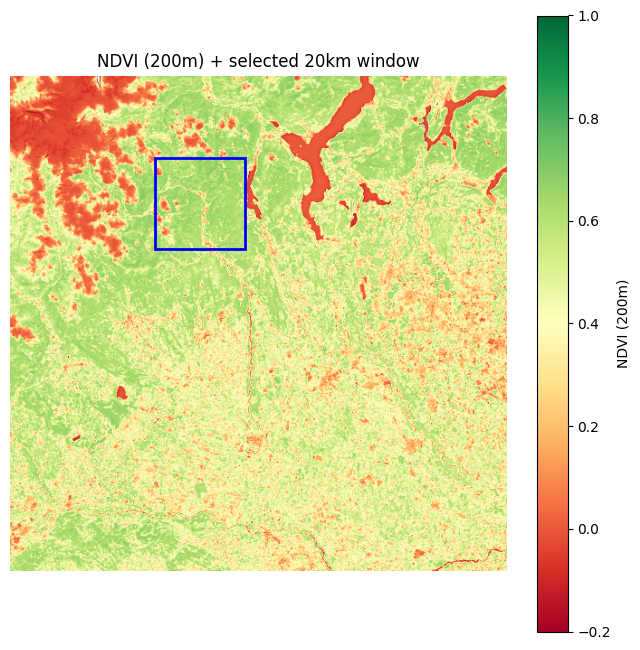

In [17]:
def window_with_highest_ndvi(ndvi_array, window_size):
    valid = np.isfinite(ndvi_array).astype(np.float32)
    a = np.nan_to_num(ndvi_array, nan=0.0).astype(np.float32)

    S = np.cumsum(np.cumsum(a, axis=0), axis=1)
    C = np.cumsum(np.cumsum(valid, axis=0), axis=1)

    def box_sum(M):
        return (M[window_size:, window_size:]
                - M[:-window_size, window_size:]
                - M[window_size:, :-window_size]
                + M[:-window_size, :-window_size])

    sum_ndvi = box_sum(S)
    count_valid = box_sum(C)
    mean_ndvi = np.where(count_valid > 0, sum_ndvi / count_valid, -np.inf)

    y, x = np.unravel_index(np.argmax(mean_ndvi), mean_ndvi.shape)
    return x, y, float(mean_ndvi[y, x])

x0_200m, y0_200m, max_ndvi_200m = window_with_highest_ndvi(ndvi_ds_masked, roi_px_200m)
print(f"Best window top-left @200m: x={x0_200m}, y={y0_200m}, mean NDVI={max_ndvi_200m:.4f}")

plt.figure(figsize=(8,8))
plt.imshow(ndvi_ds_masked, cmap="RdYlGn", vmin=-0.2, vmax=1.0)
plt.colorbar(label="NDVI (200m)")
rect = plt.Rectangle((x0_200m, y0_200m), roi_px_200m, roi_px_200m, edgecolor="blue", facecolor="none", linewidth=2)
plt.gca().add_patch(rect)
plt.title("NDVI (200m) + selected 20km window")
plt.axis("off")
plt.show()


In [18]:
#Scale factor between 20m and target resolution of 200m
scale_factor_20m = target_resolution // 20

# Scaling x0 and y0 coordinates from 200m to 20m grid
x0_20m = int(x0_200m * scale_factor_20m)
y0_20m = int(y0_200m * scale_factor_20m)

roi_px_20m = roi_px_200m * scale_factor_20m
print(f"ROI size in pixels at 20m resolution: {roi_px_20m}x{roi_px_20m}")

ROI size in pixels at 20m resolution: 1000x1000


In [19]:
train_b05_20m = find_band_jp2(train_safe, "B05", 20)

with rasterio.open(train_b05_20m) as src20:
    window_20m = Window(x0_20m, y0_20m, roi_px_20m, roi_px_20m)
    roi_bounds_utm = window_bounds(window_20m, transform=src20.transform)
    roi_transform = src20.window_transform(window_20m)
    roi_crs = src20.crs.to_string()

roi_20m_data = {
    "crs": roi_crs,
    "bounds": {"xmin": roi_bounds_utm[0], "ymin": roi_bounds_utm[1], "xmax": roi_bounds_utm[2], "ymax": roi_bounds_utm[3]},
    "grid20": {"transform": roi_transform.to_gdal(), "width": int(roi_px_20m), "height": int(roi_px_20m)},
}

Path("roi_20m_metadata.json").write_text(json.dumps(roi_20m_data, indent=4))
print("Saved ROI template to roi_20m_metadata.json")
print("ROI bounds:", roi_20m_data["bounds"])
print("ROI grid20 transform:", roi_20m_data["grid20"]["transform"])

Saved ROI template to roi_20m_metadata.json
ROI bounds: {'xmin': 431960.0, 'ymin': 5061800.0, 'xmax': 451960.0, 'ymax': 5081800.0}
ROI grid20 transform: (431960.0, 20.0, 0.0, 5081800.0, 0.0, -20.0)


In [20]:
dst_crs, dst_transform, dst_w, dst_h, bounds = load_roi_template("roi_20m_metadata.json")
template = (dst_crs, dst_transform, dst_w, dst_h)

# Machine Learning Methods - Subject Study

## Feature Preparation

In [21]:
training_X, training_scl = build_feature_stack(train_safe, template)
print("Training feature stack shape:", training_X.shape)
print("Training SCL shape:", training_scl.shape)

training_lai_path = "LAI_ROI_20m.tif"
training_lai, lai_meta = load_and_clean_lai(training_lai_path)
print("Training LAI shape:", training_lai.shape)

mask_train = build_mask(training_scl, training_lai, keep_classes=[4, 5])

print("Mask shape:", mask_train.shape)
print("Valid fraction:", mask_train.mean())

Training feature stack shape: (1000, 1000, 7)
Training SCL shape: (1000, 1000)
Training LAI shape: (1000, 1000)
Mask shape: (1000, 1000)
Valid fraction: 0.947832


In [23]:
X_train = training_X[mask_train]
y_train = training_lai[mask_train]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("y_train stats:")
print("Min:", np.min(y_train))
print("Max:", np.max(y_train))
print("Mean:", np.mean(y_train))


X_train shape: (947832, 7)
y_train shape: (947832,)
y_train stats:
Min: 0.0
Max: 6.0
Mean: 2.847731


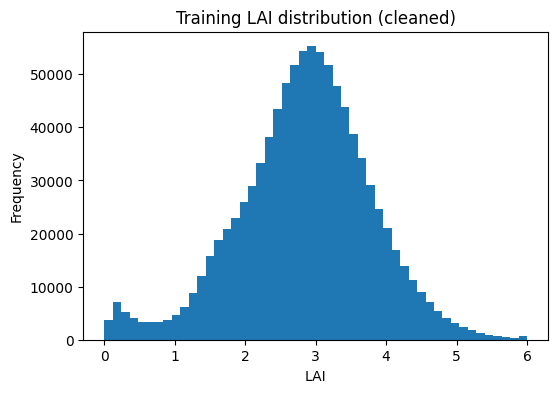

In [24]:
plt.figure(figsize=(6,4))
plt.hist(y_train, bins=50)
plt.title("Training LAI distribution (cleaned)")
plt.xlabel("LAI")
plt.ylabel("Frequency")
plt.show()


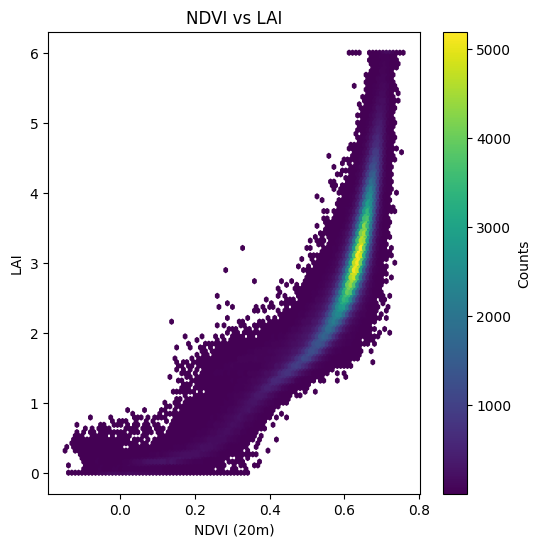

In [25]:
ndvi_train = X_train[:, -1]

plt.figure(figsize=(6,6))
plt.hexbin(ndvi_train, y_train, gridsize=100, cmap="viridis", mincnt=1)
plt.xlabel("NDVI (20m)")
plt.ylabel("LAI")
plt.colorbar(label="Counts")
plt.title("NDVI vs LAI")
plt.show()

## Baseline Model - Polynomial Regression $LAI = f(NDVI)$
The relationship between NDVI and LAI is clearly **non-linear**, as observed in the scatter plot.  
In particular, NDVI shows saturation for dense canopies (NDVI > 0.6), where large variations in LAI correspond to small changes in NDVI.

To account for this non-linearity, we adopt a **polynomial regression of degree 2**:


$LAI = \beta_0 + \beta_1 \cdot NDVI + \beta_2 \cdot NDVI^2$

This allows the model to capture curvature in the NDVI–LAI relationship.

### Why PolynomialFeatures?

The `PolynomialFeatures` transformation expands the original feature (NDVI) into:


$[1,\ NDVI,\ NDVI^2]$

The regression is still linear in the parameters (β), but non-linear in the variable NDVI.

This approach provides a fair and interpretable baseline for the NDVI-based estimation before comparing it with a multiband Machine Learning model.

### Important methodological note

The polynomial transformation is:
- **fitted only on the training set**
- **applied to the test set using the same transformation**

This avoids data leakage and ensures proper model evaluation.

Polynomial Regression (degree 2) R²: 0.8337, MSE: 0.1488


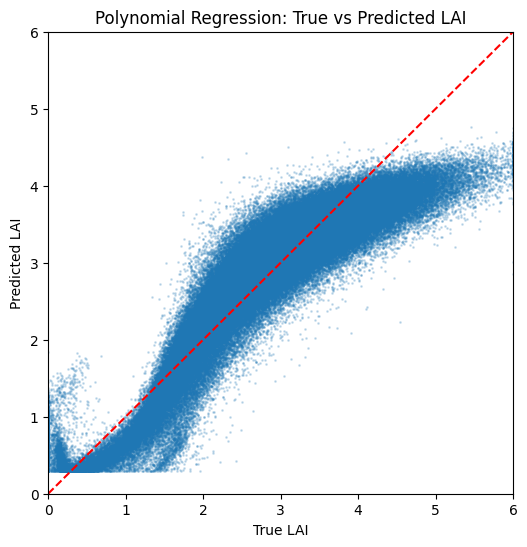

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

ndvi_feature = X_train[:, -1].reshape(-1, 1) #ndvi_20m is the last feature in X

# Train-test split
X_train_poly, X_test_poly, y_train_poly, y_test_poly = train_test_split(ndvi_feature, y_train, test_size=0.3, random_state=42)

# Transforming features to include polynomial terms up to degree 2 and then fitting a linear regression model
polynomial = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = polynomial.fit_transform(X_train_poly)
X_test_poly = polynomial.transform(X_test_poly)

model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train_poly)

# Final predictions and evaluation
y_pred_poly = model_poly.predict(X_test_poly)

r2_poly = r2_score(y_test_poly, y_pred_poly)
mse_poly = mean_squared_error(y_test_poly, y_pred_poly) 
print(f"Polynomial Regression (degree 2) R²: {r2_poly:.4f}, MSE: {mse_poly:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(y_test_poly, y_pred_poly, s=1, alpha=0.2) 
plt.xlabel("True LAI") 
plt.ylabel("Predicted LAI") 
plt.title("Polynomial Regression: True vs Predicted LAI") 
plt.plot([0, 6], [0, 6], 'r--') # Linea di riferimento y=x 
plt.xlim(0, 6) 
plt.ylim(0, 6) 
plt.show()

## Random Forest

### Train-Test Split  pixel wise (Scikit-Learn)

In [27]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

print("Train size:", X_tr.shape)
print("Test size :", X_te.shape)

Train size: (758265, 7)
Test size : (189567, 7)


In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

rf = RandomForestRegressor(n_estimators=200, max_depth=None, random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)

y_pred = rf.predict(X_te)

r2 = r2_score(y_te, y_pred)
rmse = np.sqrt(mean_squared_error(y_te, y_pred))
bias = np.mean(y_pred - y_te)

print("R²:", r2)
print("RMSE:", rmse)
print("Bias:", bias)

R²: 0.9971436692367214
RMSE: 0.050632565218850054
Bias: -0.0004431653607560637


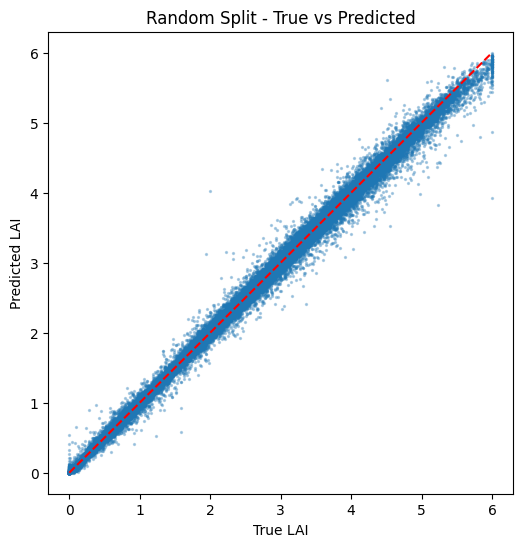

In [29]:
plt.figure(figsize=(6,6))
plt.scatter(y_te, y_pred, s=2, alpha=0.3)
plt.plot([0,6],[0,6], 'r--')
plt.xlabel("True LAI")
plt.ylabel("Predicted LAI")
plt.title("Random Split - True vs Predicted")
plt.show()

In [30]:
feature_names = ["B05","B06","B07","B8A","B11","B12","NDVI"]

importances = rf.feature_importances_

for name, imp in sorted(zip(feature_names, importances), key=lambda x: -x[1]):
    print(f"{name:>5}  {imp:.4f}")


 NDVI  0.8669
  B8A  0.0492
  B12  0.0310
  B06  0.0233
  B11  0.0228
  B07  0.0055
  B05  0.0013


### Spatial Spilt 75-25

In [31]:
H, W, C = training_X.shape
split_spatial = int(0.75 * W)

print("Width:", W)
print("Split spatial:", split_spatial)

Width: 1000
Split spatial: 750


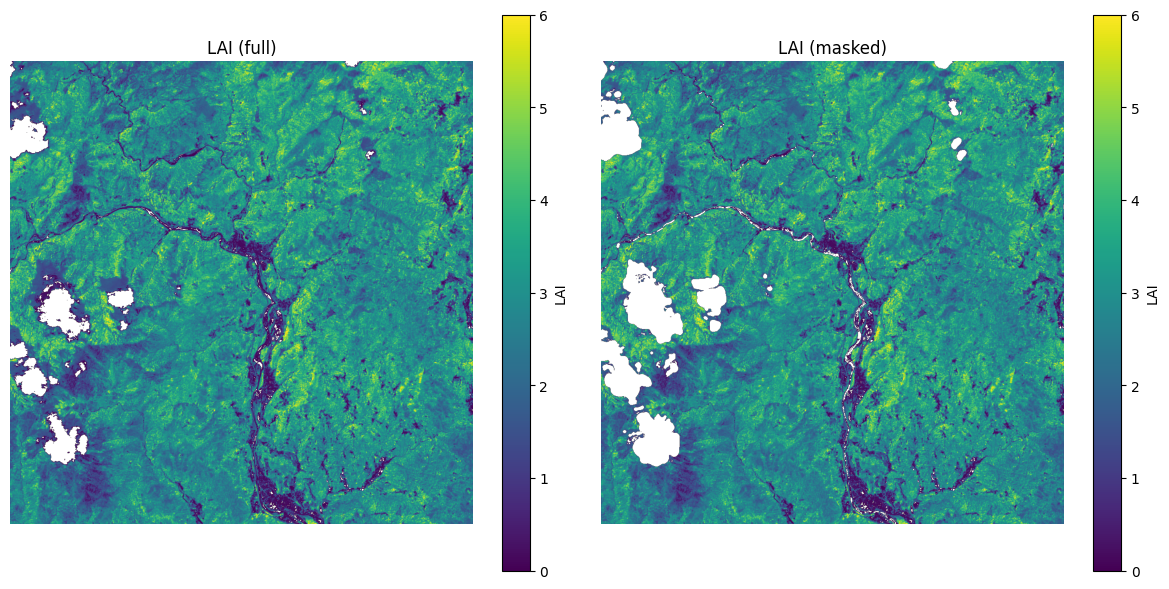

In [32]:
#show LAI without mask and with mask
lai_full = training_lai
lai_masked = np.where(mask_train, training_lai, np.nan)
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(lai_full, vmin=0, vmax=6, cmap="viridis")
plt.colorbar(label="LAI")
plt.title("LAI (full)")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(lai_masked, vmin=0, vmax=6, cmap="viridis")
plt.colorbar(label="LAI")
plt.title("LAI (masked)")
plt.axis("off")
plt.tight_layout()
plt.show()

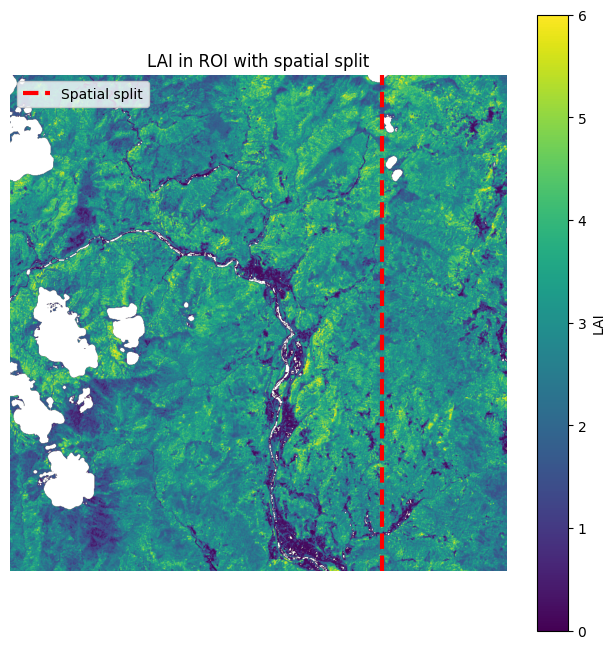

In [34]:
#show LAI ROI with thick vertical line indicating spatial split
plt.figure(figsize=(8,8))
plt.imshow(lai_masked, cmap="viridis", vmin=0, vmax=6)
plt.colorbar(label="LAI")
plt.axvline(split_spatial, color="red", linestyle="--", linewidth=3, label="Spatial split")
plt.title("LAI in ROI with spatial split")
plt.legend()
plt.axis("off")
plt.show()

In [36]:
train_spatial_mask = np.zeros((H, W), dtype=bool)
test_spatial_mask = np.zeros((H, W), dtype=bool)

train_spatial_mask[:, :split_spatial] = True
test_spatial_mask[:, split_spatial:] = True

train_spatial_mask = train_spatial_mask & mask_train
test_spatial_mask = test_spatial_mask & mask_train

print("Train spatial mask valid fraction:", train_spatial_mask.mean())
print("Test spatial mask valid fraction:", test_spatial_mask.mean())

Train spatial mask valid fraction: 0.699331
Test spatial mask valid fraction: 0.248501


In [37]:
X_tr_spatial = training_X[train_spatial_mask]
y_tr_spatial = training_lai[train_spatial_mask]
X_te_spatial = training_X[test_spatial_mask]
y_te_spatial = training_lai[test_spatial_mask]

print("Spatial Train size:", X_tr_spatial.shape)
print("Spatial Test size :", X_te_spatial.shape)

rf_spatial = RandomForestRegressor(n_estimators=200, max_depth=None, random_state=42, n_jobs=-1)

rf_spatial.fit(X_tr_spatial, y_tr_spatial)
y_pred_spatial = rf_spatial.predict(X_te_spatial)

r2_spatial = r2_score(y_te_spatial, y_pred_spatial)
rmse_spatial = np.sqrt(mean_squared_error(y_te_spatial, y_pred_spatial))
bias_spatial = np.mean(y_pred_spatial - y_te_spatial)

print("Spatial Split R²:", r2_spatial)
print("Spatial Split RMSE:", rmse_spatial)
print("Spatial Split Bias:", bias_spatial)

Spatial Train size: (699331, 7)
Spatial Test size : (248501, 7)
Spatial Split R²: 0.9969943792360665
Spatial Split RMSE: 0.04686650403867799
Spatial Split Bias: -0.0058604146158743545


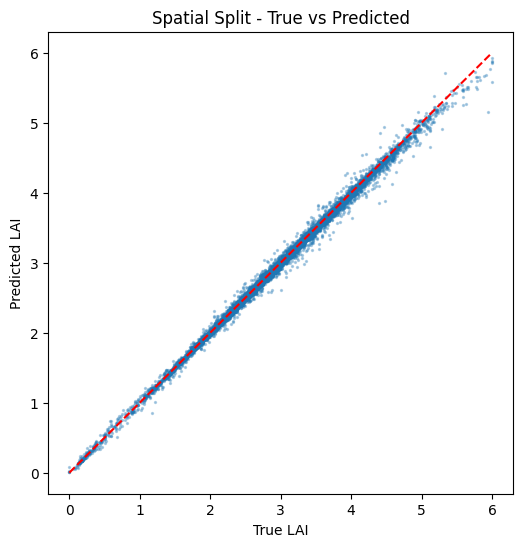

In [38]:
plt.figure(figsize=(6,6))
plt.scatter(y_te_spatial[::20], y_pred_spatial[::20], s=2, alpha=0.3)
plt.plot([0,6],[0,6],'r--')
plt.xlabel("True LAI")
plt.ylabel("Predicted LAI")
plt.title("Spatial Split - True vs Predicted")
plt.show()


In [39]:
print("Mean Lai Training: ", np.mean(y_tr_spatial))
print("Mean Lai Test (spatial split): ", np.mean(y_te_spatial))

Mean Lai Training:  2.8081167
Mean Lai Test (spatial split):  2.9592135


# Cross Year Study

Cross-year X shape: (286326, 7)
Cross-year y shape: (286326,)


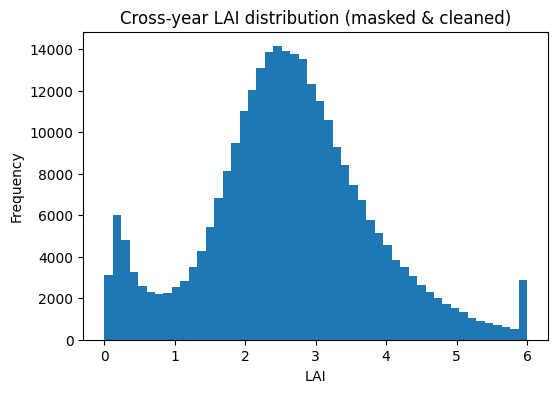

In [40]:
cross_year_safe = next(cross_path.glob("S2B_MSIL2A_20240823T101559_N0511_R065_T32TMR_20240823T145151.SAFE"))
cross_year_lai_path = Path("./CY_LAI_ROI_20m.tif")

cross_year_X, cross_year_scl = build_feature_stack(cross_year_safe, template)
cross_year_lai_clean, _ = load_and_clean_lai(cross_year_lai_path)

mask_cross_year = build_mask(cross_year_scl, cross_year_lai_clean, keep_classes=[4, 5, 6, 7])

X_cross_year = cross_year_X[mask_cross_year]
y_cross_year = cross_year_lai_clean[mask_cross_year]

print("Cross-year X shape:", X_cross_year.shape)
print("Cross-year y shape:", y_cross_year.shape)

plt.figure(figsize=(6,4))
plt.hist(y_cross_year, bins=50)
plt.xlabel("LAI")
plt.ylabel("Frequency")
plt.title("Cross-year LAI distribution (masked & cleaned)")
plt.show()


In [41]:
y_pred_cross_year = rf_spatial.predict(X_cross_year)

r2_cy = r2_score(y_cross_year, y_pred_cross_year)
rmse_cy = np.sqrt(mean_squared_error(y_cross_year, y_pred_cross_year))
bias_cy = np.mean(y_pred_cross_year - y_cross_year)

print("Cross-year R²:", r2_cy)
print("Cross-year RMSE:", rmse_cy)
print("Cross-year Bias:", bias_cy)


Cross-year R²: 0.8606153623694184
Cross-year RMSE: 0.4426524291356201
Cross-year Bias: -0.21478756798919366


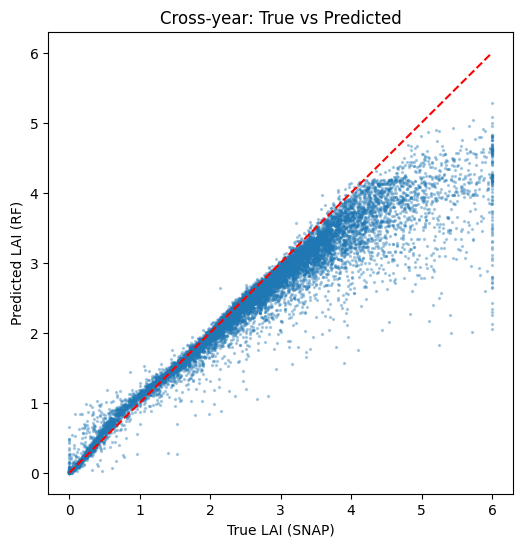

In [42]:
plt.figure(figsize=(6,6))
plt.scatter(y_cross_year[::20], y_pred_cross_year[::20], s=2, alpha=0.3)
plt.plot([0,6],[0,6],'r--')
plt.xlabel("True LAI (SNAP)")
plt.ylabel("Predicted LAI (RF)")
plt.title("Cross-year: True vs Predicted")
plt.show()

In [43]:
print("Mean LAI 2024:", np.mean(y_cross_year))
print("Mean prediction 2024:", np.mean(y_pred_cross_year))


Mean LAI 2024: 2.6201887
Mean prediction 2024: 2.405401231184707



--- TRAIN (Jul 2021) ---
N pixels: 947832
Mean: 2.847731
Std : 0.94605047
P50: 2.893
P75: 3.452
P90: 3.991
P95: 4.332
P99: 5.007
% LAI > 4: 0.09833071683589496
% LAI > 5: 0.01022860591328421

--- CROSS-YEAR (Aug 2024) ---
N pixels: 286326
Mean: 2.6201887
Std : 1.185647
P50: 2.600
P75: 3.307
P90: 4.107
P95: 4.670
P99: 5.888
% LAI > 4: 0.11348253389493096
% LAI > 5: 0.03265159293951649


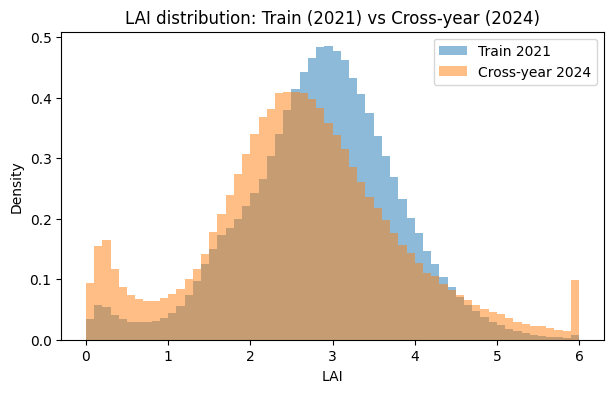

In [44]:
def summary_lai(y, name):
    y = np.asarray(y)
    print(f"\n--- {name} ---")
    print("N pixels:", y.size)
    print("Mean:", y.mean())
    print("Std :", y.std())
    for q in [50, 75, 90, 95, 99]:
        print(f"P{q}: {np.percentile(y, q):.3f}")
    print("% LAI > 4:", (y > 4).mean())
    print("% LAI > 5:", (y > 5).mean())

summary_lai(y_train, "TRAIN (Jul 2021)")
summary_lai(y_cross_year, "CROSS-YEAR (Aug 2024)")

plt.figure(figsize=(7,4))
plt.hist(y_train, bins=60, alpha=0.5, density=True, label="Train 2021")
plt.hist(y_cross_year, bins=60, alpha=0.5, density=True, label="Cross-year 2024")
plt.xlabel("LAI")
plt.ylabel("Density")
plt.title("LAI distribution: Train (2021) vs Cross-year (2024)")
plt.legend()
plt.show()


In [45]:
feature_names = ["B05","B06","B07","B8A","B11","B12","NDVI"]

def feature_summary(X, name):
    print(f"\n=== {name} feature summary ===")
    for i, f in enumerate(feature_names):
        v = X[:, i]
        print(f"{f:>4}  mean={v.mean():.4f}  std={v.std():.4f}  p1={np.percentile(v,1):.4f}  p99={np.percentile(v,99):.4f}")

feature_summary(X_train, "TRAIN (Jul 2021)")
feature_summary(X_cross_year, "CROSS-YEAR (Aug 2024)")



=== TRAIN (Jul 2021) feature summary ===
 B05  mean=0.2044  std=0.0278  p1=0.1616  p99=0.2952
 B06  mean=0.4589  std=0.0735  p1=0.2747  p99=0.6511
 B07  mean=0.5394  std=0.0928  p1=0.2933  p99=0.7652
 B8A  mean=0.5700  std=0.0968  p1=0.3046  p99=0.8029
 B11  mean=0.3327  std=0.0422  p1=0.2293  p99=0.4474
 B12  mean=0.2120  std=0.0339  p1=0.1613  p99=0.3387
NDVI  mean=0.5959  std=0.1035  p1=0.1440  p99=0.7013

=== CROSS-YEAR (Aug 2024) feature summary ===
 B05  mean=0.2159  std=0.0445  p1=0.1628  p99=0.3799
 B06  mean=0.4125  std=0.0791  p1=0.2598  p99=0.6709
 B07  mean=0.4970  std=0.1043  p1=0.2839  p99=0.8186
 B8A  mean=0.5399  std=0.1164  p1=0.2895  p99=0.8926
 B11  mean=0.3367  std=0.0564  p1=0.2051  p99=0.5120
 B12  mean=0.2182  std=0.0495  p1=0.1486  p99=0.4048
NDVI  mean=0.5011  std=0.1172  p1=0.0778  p99=0.6428


/var/folders/q7/2mxs7f6529550js05ydzbwfm0000gn/T/ipykernel_84223/525931123.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


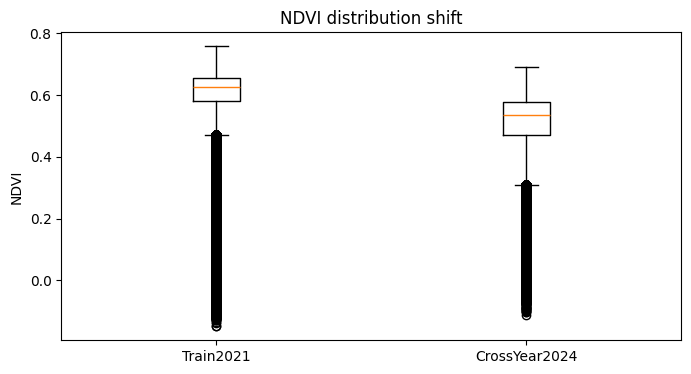

In [46]:
import pandas as pd

df = pd.DataFrame({
    "NDVI": np.concatenate([X_train[:, -1], X_cross_year[:, -1]]),
    "B8A":  np.concatenate([X_train[:, 3],  X_cross_year[:, 3]]),
    "B12":  np.concatenate([X_train[:, 5],  X_cross_year[:, 5]]),
    "set":  ["Train2021"] * X_train.shape[0] + ["CrossYear2024"] * X_cross_year.shape[0]
})

plt.figure(figsize=(8,4))
plt.boxplot(
    [df[df["set"]=="Train2021"]["NDVI"], df[df["set"]=="CrossYear2024"]["NDVI"]],
    labels=["Train2021","CrossYear2024"]
)
plt.title("NDVI distribution shift")
plt.ylabel("NDVI")
plt.show()


# Cross Season Study

In [47]:
# --- CROSS-SEASON (Oct 2021) paths ---
cross_season_safe = next(cross_path.glob("S2A_MSIL2A_20211013T101951_N0500_R065_T32TMR_20230115T052455.SAFE"))
cross_season_lai_path = Path("./CS_LAI_ROI_20mt.tif")   # <-- metti il nome reale del tuo file

# --- Extract features + SCL ---
cross_season_X, cross_season_scl = build_feature_stack(cross_season_safe, template)

# --- Load + clean LAI ---
cross_season_lai_clean, _ = load_and_clean_lai(cross_season_lai_path)

# --- Valid mask ---
mask_cross_season = build_mask(cross_season_scl, cross_season_lai_clean, keep_classes=[4,5,6,7])

# --- Flatten to samples ---
X_cross_season = cross_season_X[mask_cross_season]
y_cross_season = cross_season_lai_clean[mask_cross_season]

print("Cross-season X:", X_cross_season.shape)
print("Cross-season y:", y_cross_season.shape)
print("Cross-season LAI mean:", np.mean(y_cross_season))
print("Cross-season % LAI>4:", np.mean(y_cross_season > 4))

Cross-season X: (870324, 7)
Cross-season y: (870324,)
Cross-season LAI mean: 1.5795884
Cross-season % LAI>4: 0.0019912124680004227


In [48]:
y_pred_cross_season = rf_spatial.predict(X_cross_season)

r2_cs = r2_score(y_cross_season, y_pred_cross_season)
rmse_cs = np.sqrt(mean_squared_error(y_cross_season, y_pred_cross_season))
bias_cs = np.mean(y_pred_cross_season - y_cross_season)

print("Cross-season R²:", r2_cs)
print("Cross-season RMSE:", rmse_cs)
print("Cross-season Bias:", bias_cs)


Cross-season R²: 0.8271384522620189
Cross-season RMSE: 0.2530986021815335
Cross-season Bias: 0.1965200410875246


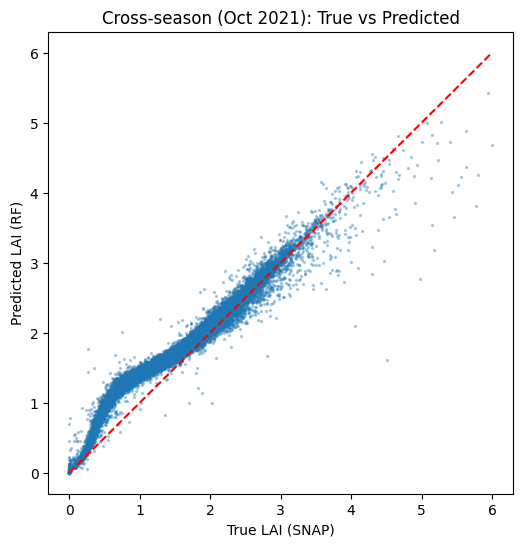

In [49]:
plt.figure(figsize=(6,6))
plt.scatter(y_cross_season[::20], y_pred_cross_season[::20], s=2, alpha=0.3)
plt.plot([0,6],[0,6],'r--')
plt.xlabel("True LAI (SNAP)")
plt.ylabel("Predicted LAI (RF)")
plt.title("Cross-season (Oct 2021): True vs Predicted")
plt.show()


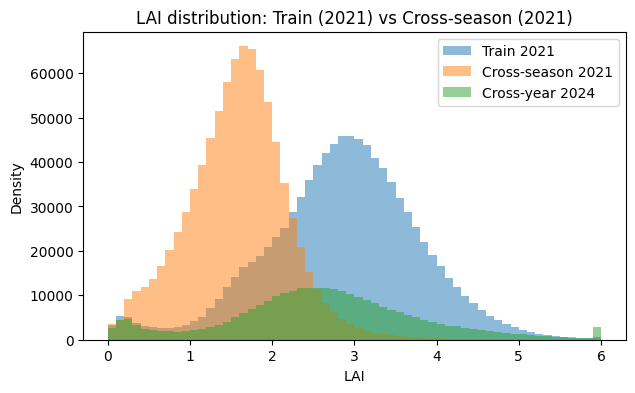

In [ ]:
plt.figure(figsize=(7,4))
plt.hist(y_train, bins=60, alpha=0.5, density=True, label="Train 2021")
plt.hist(y_cross_season, bins=60, alpha=0.5, density=True, label="Cross-season 2021")
plt.hist(y_cross_year, bins=60, alpha=0.5, density=True, label="Cross-year 2024")
plt.xlabel("LAI")
plt.ylabel("Density")
plt.title("LAI distribution: Train (2021) vs Cross-season (2021)")
plt.legend()
plt.show()

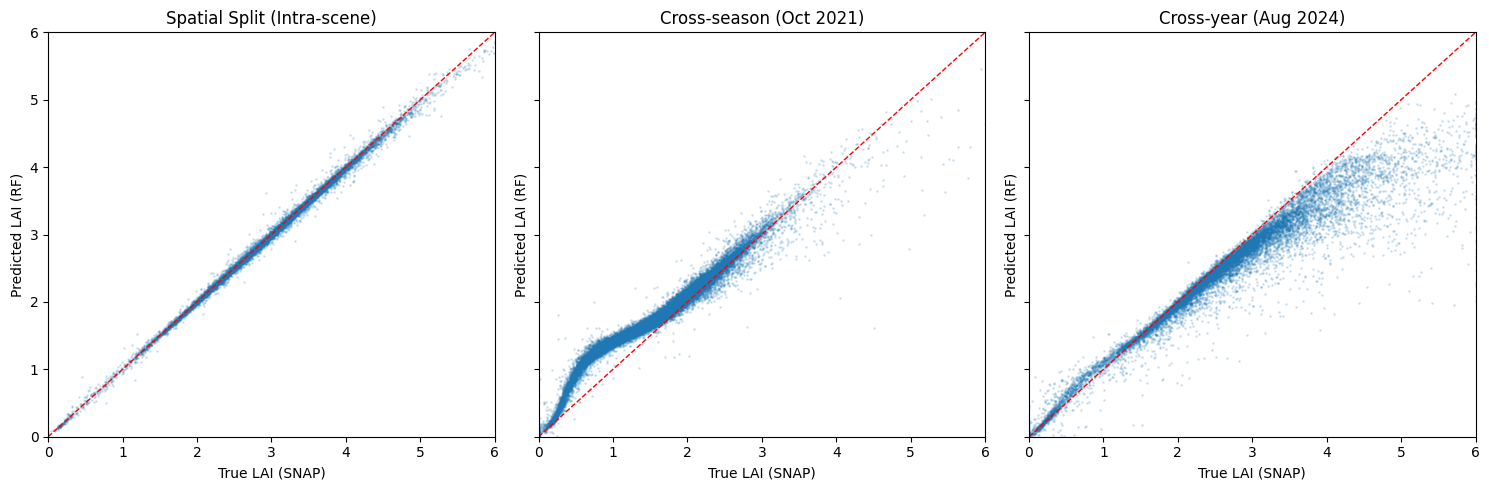

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def scatter_panel(ax, y_true, y_pred, title):
    ax.scatter(y_true[::20], y_pred[::20], s=1, alpha=0.15)
    ax.plot([0, 6], [0, 6], 'r--', linewidth=1)
    ax.set_xlim(0, 6)
    ax.set_ylim(0, 6)
    ax.set_xlabel("True LAI (SNAP)")
    ax.set_ylabel("Predicted LAI (RF)")
    ax.set_title(title)
    ax.grid(False)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

# Spatial split
scatter_panel(
    axes[0],
    y_te_spatial,
    rf_spatial.predict(X_te_spatial),
    "Spatial Split (Intra-scene)"
)

# Cross-season
scatter_panel(
    axes[1],
    y_cross_season,
    y_pred_cross_season,
    "Cross-season (Oct 2021)"
)

# Cross-year
scatter_panel(
    axes[2],
    y_cross_year,
    y_pred_cross_year,
    "Cross-year (Aug 2024)"
)

plt.tight_layout()
plt.show()


# BACKUP STUDIES

Valid pixels 2021: 949565
Valid pixels 2024: 274324
Valid pixels both: 269065


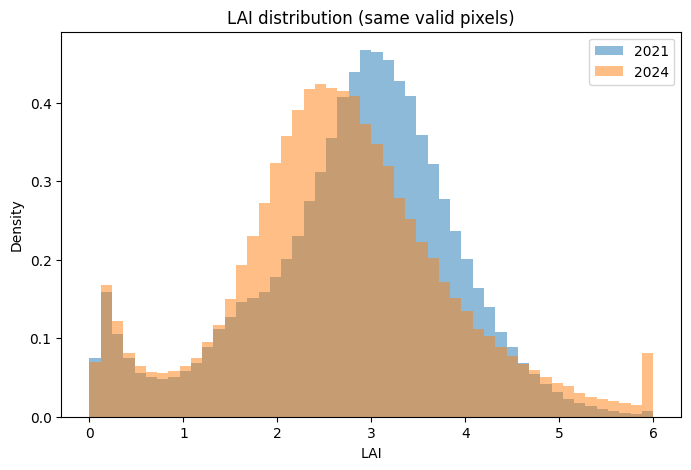

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Mask vegetation + bare soil (modificabile)
keep_classes = [4, 5]

scl_2021 = training_scl
scl_2024 = cross_year_scl
lai_2021 = training_lai
lai_2024 = cross_year_lai_clean

mask_2021 = np.isin(scl_2021, keep_classes)
mask_2024 = np.isin(scl_2024, keep_classes)

# Intersection mask
mask_both = mask_2021 & mask_2024

lai21_both = lai_2021[mask_both]
lai24_both = lai_2024[mask_both]

print("Valid pixels 2021:", mask_2021.sum())
print("Valid pixels 2024:", mask_2024.sum())
print("Valid pixels both:", mask_both.sum())

plt.figure(figsize=(8,5))
plt.hist(lai21_both, bins=50, density=True, alpha=0.5, label="2021")
plt.hist(lai24_both, bins=50, density=True, alpha=0.5, label="2024")
plt.legend()
plt.title("LAI distribution (same valid pixels)")
plt.xlabel("LAI")
plt.ylabel("Density")
plt.show()

High LAI >5 pixels 2021: 9695
High LAI >5 pixels 2024: 9174


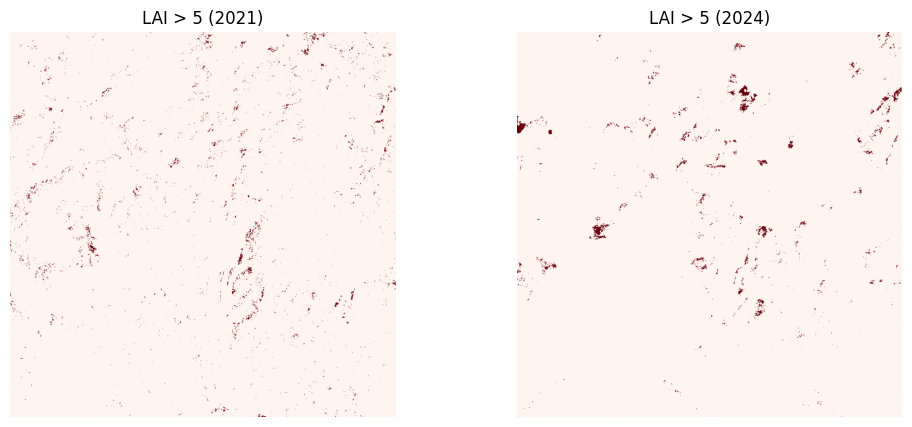

In [ ]:
high21 = (lai_2021 > 5) & mask_2021
high24 = (lai_2024 > 5) & mask_2024

print("High LAI >5 pixels 2021:", high21.sum())
print("High LAI >5 pixels 2024:", high24.sum())

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(high21, cmap="Reds")
plt.title("LAI > 5 (2021)")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(high24, cmap="Reds")
plt.title("LAI > 5 (2024)")
plt.axis("off")

plt.show()

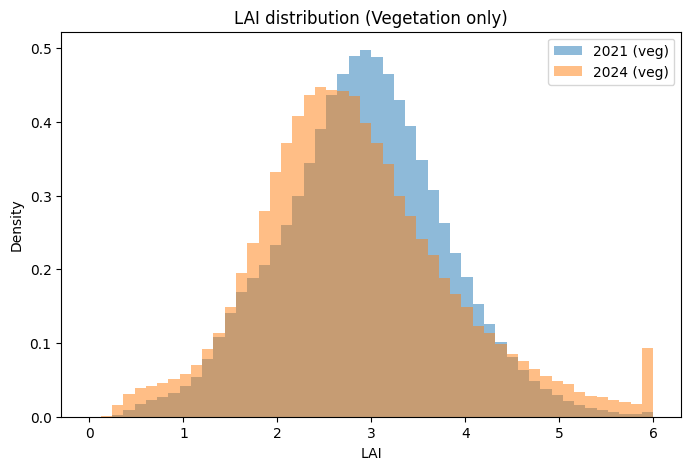

In [ ]:
mask_veg21_July = scl_2021 == 4
mask_veg24 = scl_2024 == 4
mask_veg21

lai21_veg = lai_2021[mask_veg21]
lai24_veg = lai_2024[mask_veg24]

plt.figure(figsize=(8,5))
plt.hist(lai21_veg, bins=50, density=True, alpha=0.5, label="2021 (veg)")
plt.hist(lai24_veg, bins=50, density=True, alpha=0.5, label="2024 (veg)")
plt.legend()
plt.title("LAI distribution (Vegetation only)")
plt.xlabel("LAI")
plt.ylabel("Density")
plt.show()